In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 

In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet'
df = pd.read_parquet(file, engine='pyarrow')

In [3]:
df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas
1,36.05,-91.05,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,47.916667,0.0,33.333333,0.000000,2.083333,Arkansas
2,36.05,-90.95,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,1.515152,0.0,46.212121,22.727273,26.515152,Arkansas
3,36.05,-90.85,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,8.333333,0.0,65.972222,2.777778,11.805556,Arkansas
4,36.05,-90.75,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,1.515152,0.0,76.515152,0.000000,4.545455,Arkansas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-97.25,0.230,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,77.272727,22.727273,North Dakota
33395117,48.95,-97.15,0.115,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,36.111111,59.027778,Minnesota
33395118,48.95,-97.05,0.075,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,12.878788,0.757576,Minnesota
33395119,48.95,-96.95,0.025,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,25.000000,0.0,0.000000,0.000000,0.000000,Minnesota


In [4]:
df.columns

Index(['grid_lat', 'grid_lon', 'h_precip_mm', 'datetime', 'no2_mean',
       'no2_std', 'no2_sem', 'snow_ice_fraction_mean', 'snow_ice_fraction_std',
       'cv_no2', 'datetime_local', 'local_hour', 'no2_scaled_by_hour',
       'pulse_start', 'sm_surface', 'surface_temp', 'soil_temp_layer1',
       'WFPS_c', 'dominant_texture', 'pct_clay', 'pct_clay_loam', 'pct_loam',
       'pct_loamy_sand', 'pct_sand', 'pct_sandy_clay', 'pct_sandy_clay_loam',
       'pct_sandy_loam', 'pct_silt', 'pct_silt_loam', 'pct_silty_clay',
       'pct_silty_clay_loam', 'state_name'],
      dtype='object')

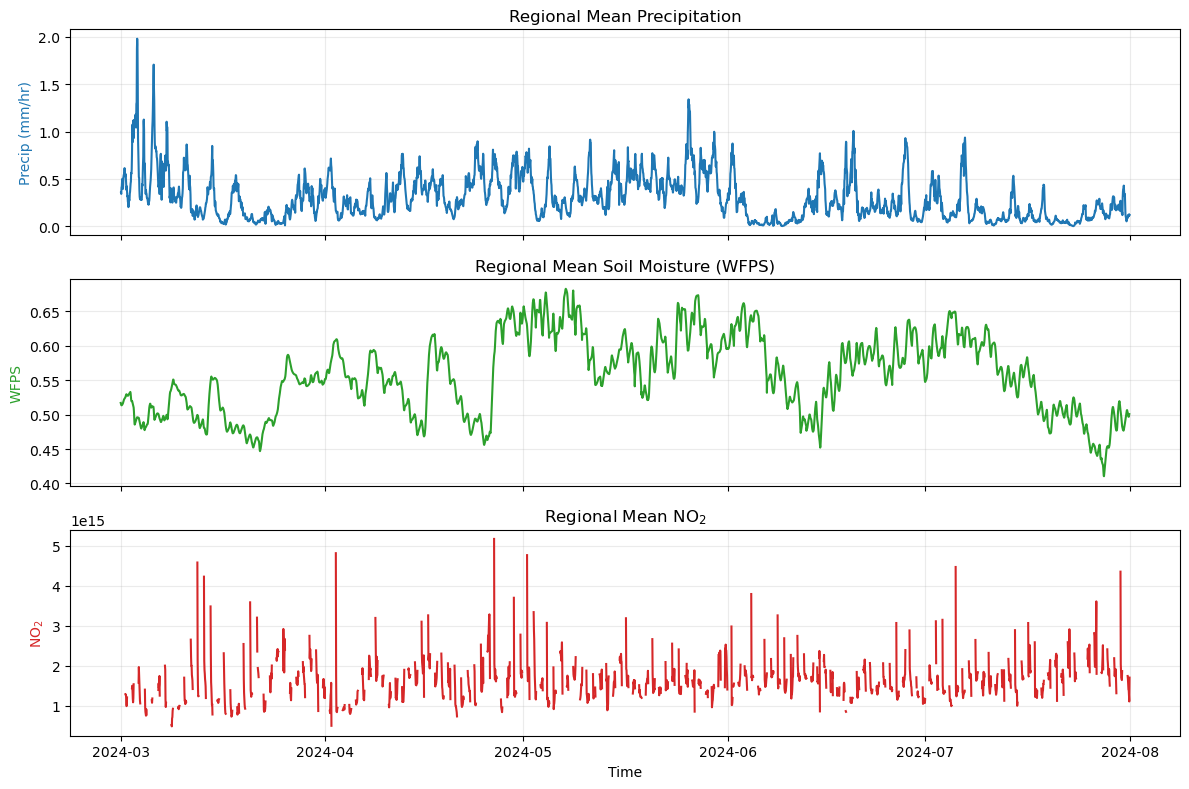

In [5]:

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

#aggregate over region 
regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean")
    )
    .reset_index()
)

# create subplots 
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 8),
    sharex=True
)

#precipitation
axes[0].plot(
    regional["datetime"],
    regional["precip"],
    color="tab:blue"
)
axes[0].set_ylabel("Precip (mm/hr)", color="tab:blue")
axes[0].set_title("Regional Mean Precipitation")
axes[0].grid(alpha=0.25)

#Soil moisture (WFPS)
axes[1].plot(
    regional["datetime"],
    regional["WFPS"],
    color="tab:green"
)
axes[1].set_ylabel("WFPS", color="tab:green")
axes[1].set_title("Regional Mean Soil Moisture (WFPS)")
axes[1].grid(alpha=0.25)

#NO2
axes[2].plot(
    regional["datetime"],
    regional["NO2"],
    color="tab:red"
)
axes[2].set_ylabel("NO$_2$", color="tab:red")
axes[2].set_title("Regional Mean NO$_2$")
axes[2].grid(alpha=0.25)

# shared x-axis
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

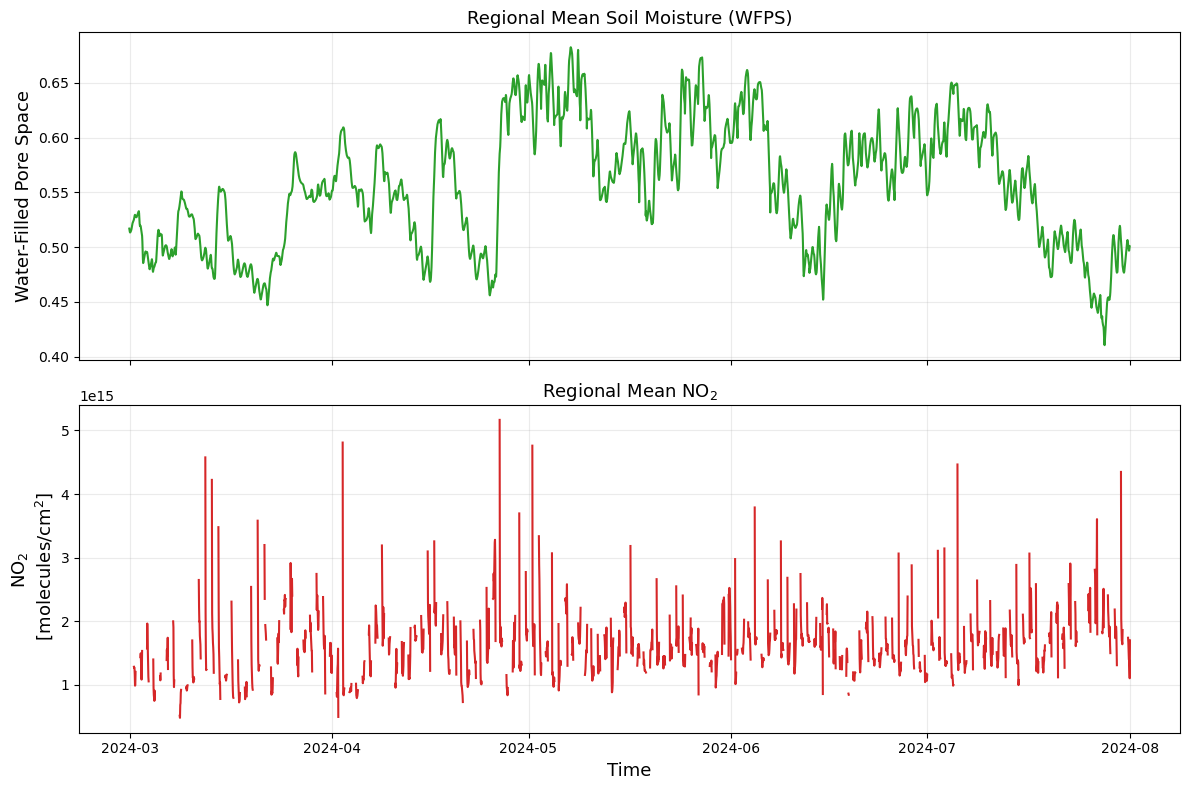

In [7]:
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

#aggregate over region 
regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean")
    )
    .reset_index()
)

# create subplots 
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True
)

# #precipitation
# axes[0].plot(
#     regional["datetime"],
#     regional["precip"],
#     color="tab:blue"
# )
# axes[0].set_ylabel("Precip (mm/hr)", color="tab:blue")
# axes[0].set_title("Regional Mean Precipitation")
# axes[0].grid(alpha=0.25)

#Soil moisture (WFPS)
axes[0].plot(
    regional["datetime"],
    regional["WFPS"],
    color="tab:green"
)
axes[0].set_ylabel("Water-Filled Pore Space", fontsize = 13)
axes[0].set_title("Regional Mean Soil Moisture (WFPS)",fontsize=13)
axes[0].grid(alpha=0.25)

#NO2
axes[1].plot(
    regional["datetime"],
    regional["NO2"],
    color="tab:red"
)
axes[1].set_ylabel("NO$_2$ \n [molecules/cm$^2$]", fontsize=13)
axes[1].set_title("Regional Mean NO$_2$",fontsize=13)
axes[1].grid(alpha=0.25)

# shared x-axis
axes[1].set_xlabel("Time", fontsize=13)

plt.tight_layout()
#plt.savefig('global/home/users/toireasamarie/Paper_Workflow/Paper Figures/
plt.show()

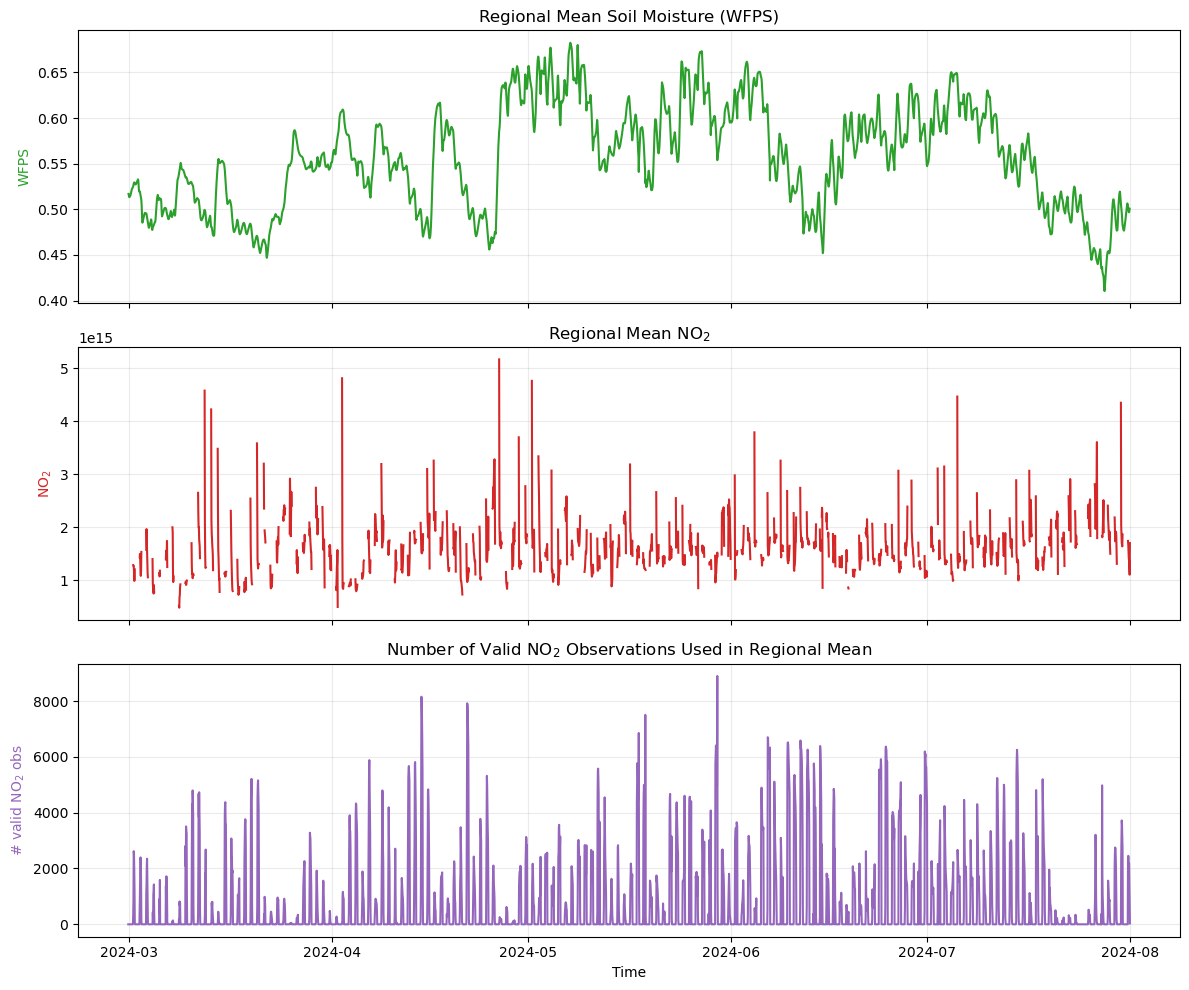

In [8]:
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# Aggregate over region
regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean"),
        n_no2_obs=("no2_mean", "count")  # counts non-NaN NO2 observations
    )
    .reset_index()
)

# Create subplots
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 10),
    sharex=True
)

# Soil moisture (WFPS)
axes[0].plot(
    regional["datetime"],
    regional["WFPS"],
    color="tab:green"
)
axes[0].set_ylabel("WFPS", color="tab:green")
axes[0].set_title("Regional Mean Soil Moisture (WFPS)")
axes[0].grid(alpha=0.25)

# NO2
axes[1].plot(
    regional["datetime"],
    regional["NO2"],
    color="tab:red"
)
axes[1].set_ylabel("NO$_2$", color="tab:red")
axes[1].set_title("Regional Mean NO$_2$")
axes[1].grid(alpha=0.25)

# Number of valid NO2 observations
axes[2].plot(
    regional["datetime"],
    regional["n_no2_obs"],
    color="tab:purple"
)
axes[2].set_ylabel("# valid NO$_2$ obs", color="tab:purple")
axes[2].set_title("Number of Valid NO$_2$ Observations Used in Regional Mean")
axes[2].grid(alpha=0.25)

# Shared x-axis
axes[2].set_xlabel("Time")

plt.tight_layout()
plt.show()

In [9]:
n_grid_cells = df[["grid_lat", "grid_lon"]].drop_duplicates().shape[0]

print(f"Number of grid cells in region: {n_grid_cells:,}")

Number of grid cells in region: 9,080


# Plots on diurnal trend 

Grid cell with most pulses: lat=36.65, lon=-89.35, pulses=4


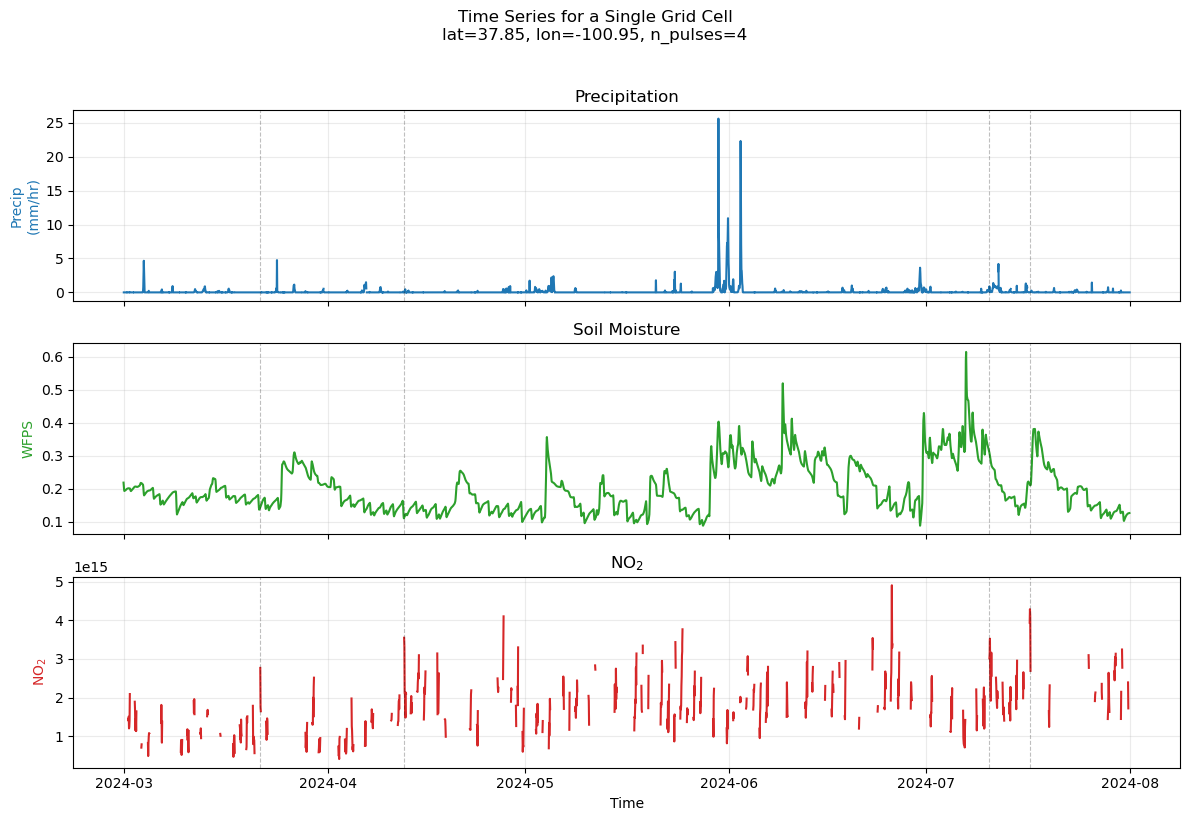

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# find grid cell with most pulses
pulse_counts = (
    df_plot[df_plot["pulse_start"] == True]
    .groupby(["grid_lat", "grid_lon"])
    .size()
    .sort_values(ascending=False)
)

top_lat, top_lon = pulse_counts.index[0]
top_n_pulses = pulse_counts.iloc[0]

print(f"Grid cell with most pulses: lat={top_lat}, lon={top_lon}, pulses={top_n_pulses}")

valid_cells = (
    df_plot.groupby(["grid_lat", "grid_lon"])
    .agg(
        n_pulses=("pulse_start", "sum"),
        total_precip=("h_precip_mm", "sum")
    )
    .reset_index()
)

valid_cells = valid_cells[
    (valid_cells["n_pulses"] > 0) &
    (valid_cells["total_precip"] > 0)
].sort_values("n_pulses", ascending=False)

top_lat = valid_cells.iloc[0]["grid_lat"]
top_lon = valid_cells.iloc[0]["grid_lon"]
top_n_pulses = valid_cells.iloc[0]["n_pulses"]

cell_df = df_plot[
    (df_plot["grid_lat"] == top_lat) &
    (df_plot["grid_lon"] == top_lon)
].sort_values("datetime").copy()


# optional: mark pulse times
pulse_times = cell_df.loc[cell_df["pulse_start"] == True, "datetime"]

# plot
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 8),
    sharex=True
)

# precipitation
axes[0].plot(cell_df["datetime"], cell_df["h_precip_mm"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue")
axes[0].set_title("Precipitation")
axes[0].grid(alpha=0.25)

# soil moisture
axes[1].plot(cell_df["datetime"], cell_df["WFPS_c"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green")
axes[1].set_title("Soil Moisture")
axes[1].grid(alpha=0.25)

# NO2
axes[2].plot(cell_df["datetime"], cell_df["no2_mean"], color="tab:red")
axes[2].set_ylabel("NO$_2$", color="tab:red")
axes[2].set_title("NO$_2$")
axes[2].set_xlabel("Time")
axes[2].grid(alpha=0.25)

# add vertical pulse markers to all panels
for ax in axes:
    for t in pulse_times:
        ax.axvline(t, color="black", linestyle="--", alpha=0.25, linewidth=0.8)

fig.suptitle(
    f"Time Series for a Single Grid Cell\n"
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, n_pulses={top_n_pulses}",
    y=1.02
)

plt.tight_layout()
plt.show()

Grid cell rank 16: lat=38.05, lon=-90.25, pulses=3, total_precip=906.08


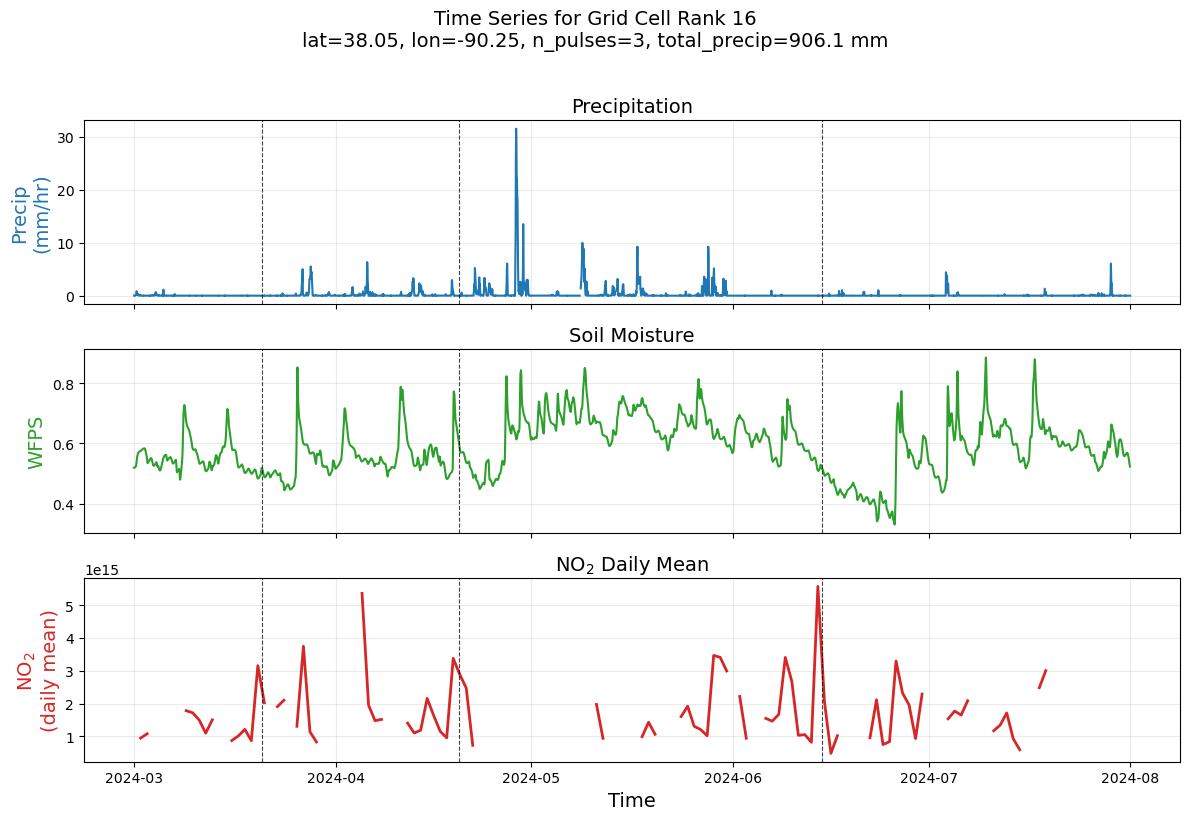

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# choose which grid cell to plot
rank = 16 # 0 = most pulses, 1 = second-most, 2 = third-most, etc.

valid_cells = (
    df_plot.groupby(["grid_lat", "grid_lon"])
    .agg(
        n_pulses=("pulse_start", "sum"),
        total_precip=("h_precip_mm", "sum")
    )
    .reset_index()
)

valid_cells = valid_cells[
    (valid_cells["n_pulses"] > 0) &
    (valid_cells["total_precip"] > 0)
].sort_values(["n_pulses", "total_precip"], ascending=False)

top_lat = valid_cells.iloc[rank]["grid_lat"]
top_lon = valid_cells.iloc[rank]["grid_lon"]
top_n_pulses = valid_cells.iloc[rank]["n_pulses"]
top_total_precip = valid_cells.iloc[rank]["total_precip"]

print(
    f"Grid cell rank {rank}: "
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"pulses={top_n_pulses}, total_precip={top_total_precip:.2f}"
)

cell_df = df_plot[
    (df_plot["grid_lat"] == top_lat) &
    (df_plot["grid_lon"] == top_lon)
].sort_values("datetime").copy()

no2_daily = (
    cell_df.set_index("datetime")["no2_mean"]
    .resample("1D")
    .mean()
)

pulse_times = cell_df.loc[cell_df["pulse_start"] == True, "datetime"]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(cell_df["datetime"], cell_df["h_precip_mm"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue",fontsize=14)
axes[0].set_title("Precipitation",fontsize=14)
axes[0].grid(alpha=0.25)

axes[1].plot(cell_df["datetime"], cell_df["WFPS_c"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green",fontsize=14)
axes[1].set_title("Soil Moisture",fontsize=14)
axes[1].grid(alpha=0.25)

axes[2].plot(no2_daily.index, no2_daily.values, color="tab:red", linewidth=2)
axes[2].set_ylabel("NO$_2$\n(daily mean)", color="tab:red",fontsize=14)
axes[2].set_title("NO$_2$ Daily Mean",fontsize=14)
axes[2].set_xlabel("Time",fontsize=14)
axes[2].grid(alpha=0.25)

for ax in axes:
    for t in pulse_times:
        ax.axvline(t, color="black", linestyle="--", alpha=0.75, linewidth=0.8)

fig.suptitle(
    f"Time Series for Grid Cell Rank {rank}\n"
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"n_pulses={top_n_pulses}, total_precip={top_total_precip:.1f} mm",
    y=1.02, fontsize=14
)

plt.tight_layout()
plt.show()

Grid cell rank 1: lat=37.75, lon=-101.05, pulses=4, total_precip=386.35


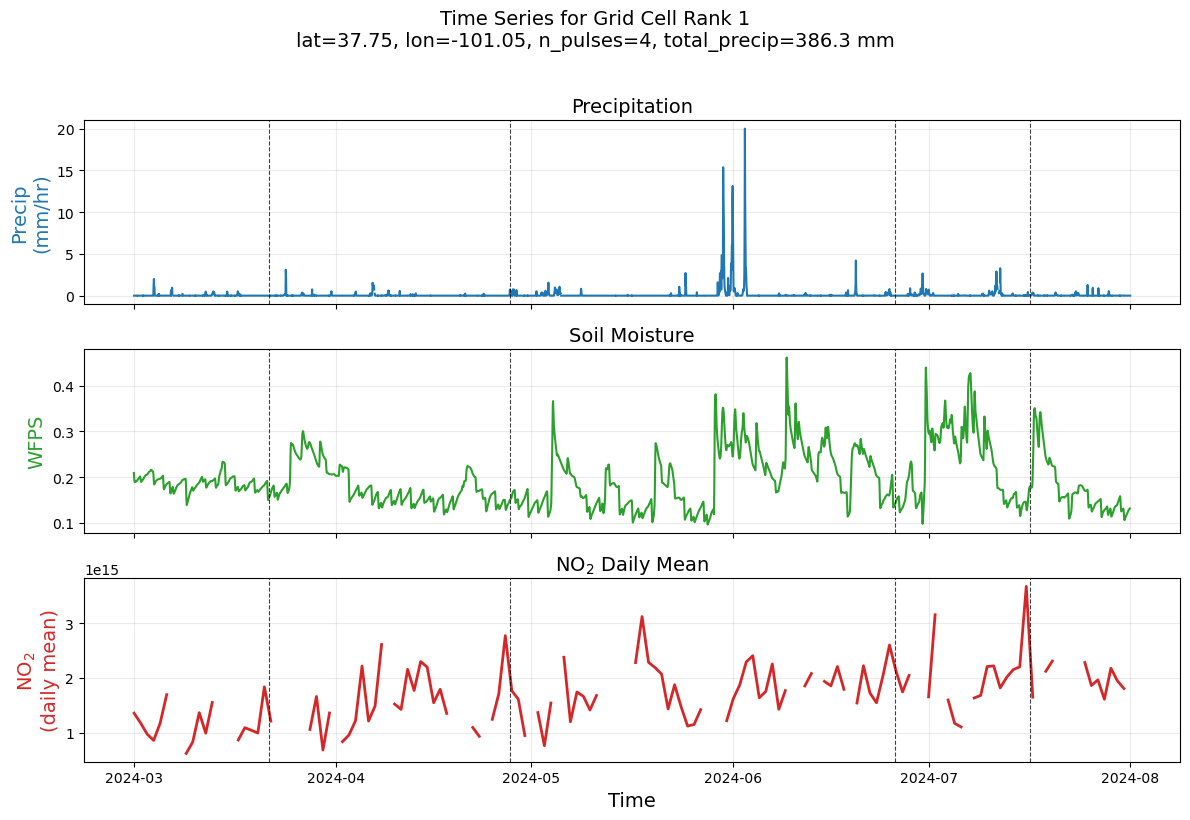

In [12]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# choose which grid cell to plot
rank = 1 # 0 = most pulses, 1 = second-most, 2 = third-most, etc.

valid_cells = (
    df_plot.groupby(["grid_lat", "grid_lon"])
    .agg(
        n_pulses=("pulse_start", "sum"),
        total_precip=("h_precip_mm", "sum")
    )
    .reset_index()
)

valid_cells = valid_cells[
    (valid_cells["n_pulses"] > 0) &
    (valid_cells["total_precip"] > 0)
].sort_values(["n_pulses", "total_precip"], ascending=False)

top_lat = valid_cells.iloc[rank]["grid_lat"]
top_lon = valid_cells.iloc[rank]["grid_lon"]
top_n_pulses = valid_cells.iloc[rank]["n_pulses"]
top_total_precip = valid_cells.iloc[rank]["total_precip"]

print(
    f"Grid cell rank {rank}: "
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"pulses={top_n_pulses}, total_precip={top_total_precip:.2f}"
)

cell_df = df_plot[
    (df_plot["grid_lat"] == top_lat) &
    (df_plot["grid_lon"] == top_lon)
].sort_values("datetime").copy()

no2_daily = (
    cell_df.set_index("datetime")["no2_mean"]
    .resample("1D")
    .mean()
)

pulse_times = cell_df.loc[cell_df["pulse_start"] == True, "datetime"]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(cell_df["datetime"], cell_df["h_precip_mm"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue",fontsize=14)
axes[0].set_title("Precipitation",fontsize=14)
axes[0].grid(alpha=0.25)

axes[1].plot(cell_df["datetime"], cell_df["WFPS_c"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green",fontsize=14)
axes[1].set_title("Soil Moisture",fontsize=14)
axes[1].grid(alpha=0.25)

axes[2].plot(no2_daily.index, no2_daily.values, color="tab:red", linewidth=2)
axes[2].set_ylabel("NO$_2$\n(daily mean)", color="tab:red",fontsize=14)
axes[2].set_title("NO$_2$ Daily Mean",fontsize=14)
axes[2].set_xlabel("Time",fontsize=14)
axes[2].grid(alpha=0.25)

for ax in axes:
    for t in pulse_times:
        ax.axvline(t, color="black", linestyle="--", alpha=0.75, linewidth=0.8)

fig.suptitle(
    f"Time Series for Grid Cell Rank {rank}\n"
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"n_pulses={top_n_pulses}, total_precip={top_total_precip:.1f} mm",
    y=1.02, fontsize=14
)

plt.tight_layout()
plt.show()

Grid cell rank 2: lat=38.75, lon=-95.05, pulses=3, total_precip=2106.35


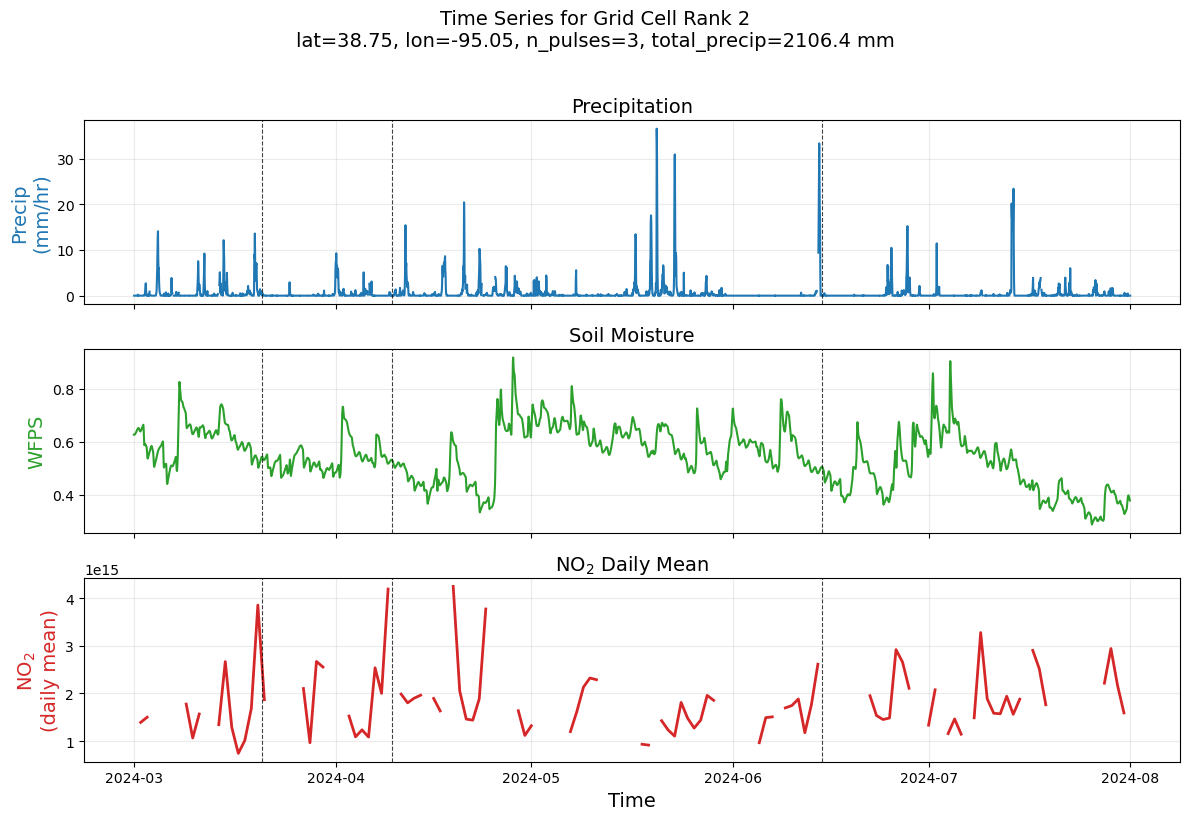

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# choose which grid cell to plot
rank = 2 # 0 = most pulses, 1 = second-most, 2 = third-most, etc.

valid_cells = (
    df_plot.groupby(["grid_lat", "grid_lon"])
    .agg(
        n_pulses=("pulse_start", "sum"),
        total_precip=("h_precip_mm", "sum")
    )
    .reset_index()
)

valid_cells = valid_cells[
    (valid_cells["n_pulses"] > 0) &
    (valid_cells["total_precip"] > 0)
].sort_values(["n_pulses", "total_precip"], ascending=False)

top_lat = valid_cells.iloc[rank]["grid_lat"]
top_lon = valid_cells.iloc[rank]["grid_lon"]
top_n_pulses = valid_cells.iloc[rank]["n_pulses"]
top_total_precip = valid_cells.iloc[rank]["total_precip"]

print(
    f"Grid cell rank {rank}: "
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"pulses={top_n_pulses}, total_precip={top_total_precip:.2f}"
)

cell_df = df_plot[
    (df_plot["grid_lat"] == top_lat) &
    (df_plot["grid_lon"] == top_lon)
].sort_values("datetime").copy()

no2_daily = (
    cell_df.set_index("datetime")["no2_mean"]
    .resample("1D")
    .mean()
)

pulse_times = cell_df.loc[cell_df["pulse_start"] == True, "datetime"]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(cell_df["datetime"], cell_df["h_precip_mm"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue",fontsize=14)
axes[0].set_title("Precipitation",fontsize=14)
axes[0].grid(alpha=0.25)

axes[1].plot(cell_df["datetime"], cell_df["WFPS_c"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green",fontsize=14)
axes[1].set_title("Soil Moisture",fontsize=14)
axes[1].grid(alpha=0.25)

axes[2].plot(no2_daily.index, no2_daily.values, color="tab:red", linewidth=2)
axes[2].set_ylabel("NO$_2$\n(daily mean)", color="tab:red",fontsize=14)
axes[2].set_title("NO$_2$ Daily Mean",fontsize=14)
axes[2].set_xlabel("Time",fontsize=14)
axes[2].grid(alpha=0.25)

for ax in axes:
    for t in pulse_times:
        ax.axvline(t, color="black", linestyle="--", alpha=0.75, linewidth=0.8)

fig.suptitle(
    f"Time Series for Grid Cell Rank {rank}\n"
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"n_pulses={top_n_pulses}, total_precip={top_total_precip:.1f} mm",
    y=1.02, fontsize=14
)

plt.tight_layout()
plt.show()

Grid cell rank 7: lat=40.95, lon=-96.15, pulses=3, total_precip=1507.90


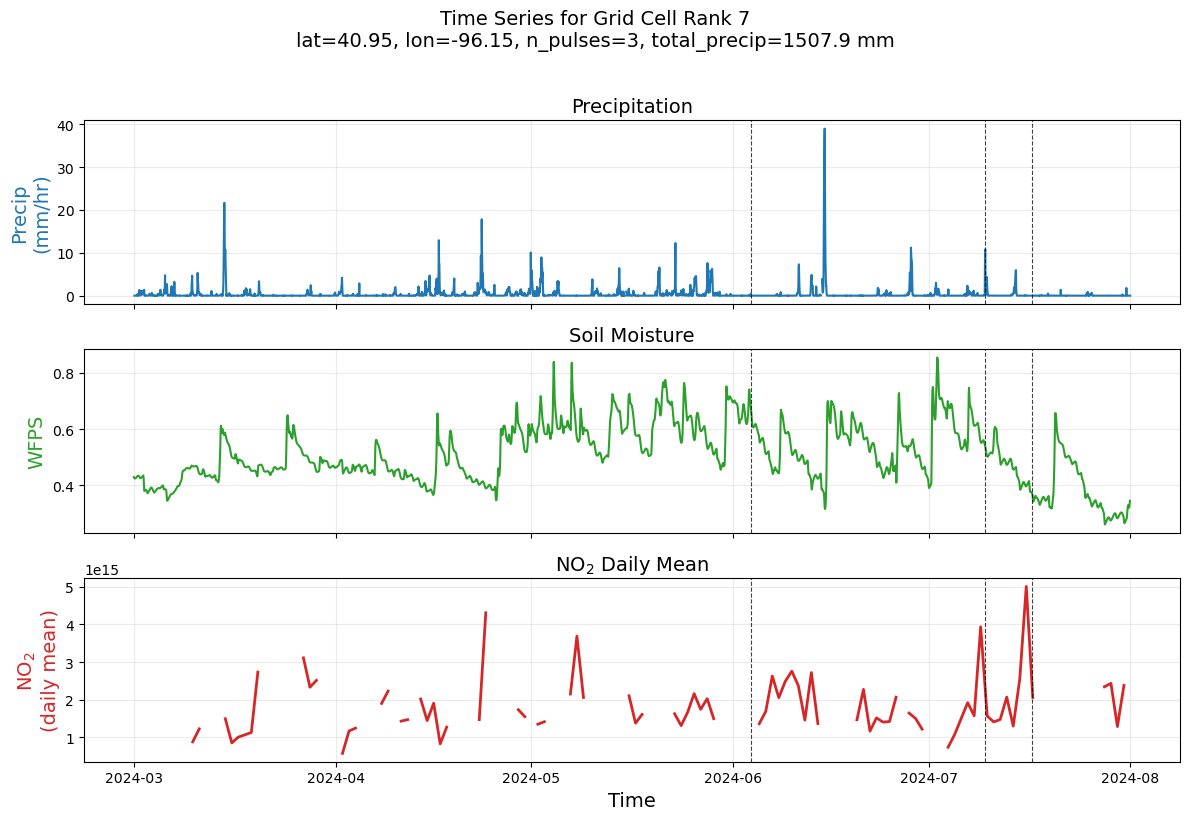

In [20]:
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# choose which grid cell to plot
rank = 7 # 0 = most pulses, 1 = second-most, 2 = third-most, etc.

valid_cells = (
    df_plot.groupby(["grid_lat", "grid_lon"])
    .agg(
        n_pulses=("pulse_start", "sum"),
        total_precip=("h_precip_mm", "sum")
    )
    .reset_index()
)

valid_cells = valid_cells[
    (valid_cells["n_pulses"] > 0) &
    (valid_cells["total_precip"] > 0)
].sort_values(["n_pulses", "total_precip"], ascending=False)

top_lat = valid_cells.iloc[rank]["grid_lat"]
top_lon = valid_cells.iloc[rank]["grid_lon"]
top_n_pulses = valid_cells.iloc[rank]["n_pulses"]
top_total_precip = valid_cells.iloc[rank]["total_precip"]

print(
    f"Grid cell rank {rank}: "
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"pulses={top_n_pulses}, total_precip={top_total_precip:.2f}"
)

cell_df = df_plot[
    (df_plot["grid_lat"] == top_lat) &
    (df_plot["grid_lon"] == top_lon)
].sort_values("datetime").copy()

no2_daily = (
    cell_df.set_index("datetime")["no2_mean"]
    .resample("1D")
    .mean()
)

pulse_times = cell_df.loc[cell_df["pulse_start"] == True, "datetime"]

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(cell_df["datetime"], cell_df["h_precip_mm"], color="tab:blue")
axes[0].set_ylabel("Precip\n(mm/hr)", color="tab:blue",fontsize=14)
axes[0].set_title("Precipitation",fontsize=14)
axes[0].grid(alpha=0.25)

axes[1].plot(cell_df["datetime"], cell_df["WFPS_c"], color="tab:green")
axes[1].set_ylabel("WFPS", color="tab:green",fontsize=14)
axes[1].set_title("Soil Moisture",fontsize=14)
axes[1].grid(alpha=0.25)

axes[2].plot(no2_daily.index, no2_daily.values, color="tab:red", linewidth=2)
axes[2].set_ylabel("NO$_2$\n(daily mean)", color="tab:red",fontsize=14)
axes[2].set_title("NO$_2$ Daily Mean",fontsize=14)
axes[2].set_xlabel("Time",fontsize=14)
axes[2].grid(alpha=0.25)

for ax in axes:
    for t in pulse_times:
        ax.axvline(t, color="black", linestyle="--", alpha=0.75, linewidth=0.8)

fig.suptitle(
    f"Time Series for Grid Cell Rank {rank}\n"
    f"lat={top_lat:.2f}, lon={top_lon:.2f}, "
    f"n_pulses={top_n_pulses}, total_precip={top_total_precip:.1f} mm",
    y=1.02, fontsize=14
)

plt.tight_layout()
plt.show()